In [1]:
from google.colab import drive


# Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# for the given speech file, first compute the Frequency Spectrum and then Compute the Spectrogram

# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from google.colab import drive

from IPython.display import Audio, display

import os
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

import numpy as np
import pandas as pd
import os
import librosa
import librosa.display
import IPython
from IPython.display import Audio
from IPython.display import Image
import matplotlib.pyplot as plt

# Mount Google Drive
drive.mount('/content/drive')

# Import os for file path operations
import os

folder_path = "/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Speech_Actors_01-24"

data = pd.DataFrame(columns=['Emotion', 'Emotion intensity', 'Gender', 'Path'])

# Check if the file exists
if not os.path.exists(folder_path):
    raise FileNotFoundError(f"The folder {folder_path} does not exist. Please check the path.")

folders = os.listdir(folder_path)
folder_path2 = "/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Song_Actors_01-24"
folders.sort()
print(folders)

# class_to_idx = {cls_name: idx for idx, cls_name in enumerate(classes)}
label_dict = {0: 'neutral', 1: 'calm', 2: 'happy', 3: 'sad', 4: 'angry', 5: 'fearful', 6: 'disgust', 7 : 'surprised'}
class_to_idx = {'neutral': 0, 'calm': 1, 'happy': 2, 'sad': 3, 'angry': 4, 'fearful': 5, 'disgust': 6, 'surprised': 7}
print(class_to_idx)

train_files = []
test_files = []
train_labels = []
test_labels = []
audio_files = []
audio_labels = []

for i, folder_name in enumerate(folders):
    folder_dir = os.path.join(folder_path, folder_name)
    folder_dir2 = os.path.join(folder_path2, folder_name)
    if os.path.isdir(folder_dir):
        for audio_file in os.listdir(folder_dir):
            if audio_file.endswith('.wav'):
                identifiers = audio_file.split('.')[0].split('-')
                emotion = int(identifiers[2]) - 1
                if (emotion >= 5):
                 continue
                emotion_intensity = 'normal' if int(identifiers[3]) == 1 else 'strong'
                gender = 'female' if int(identifiers[6]) % 2 == 0 else 'male'

                new_row = pd.DataFrame({
                    "Emotion": [emotion],
                    "Emotion intensity": [emotion_intensity],
                    "Gender": [gender],
                    "Path": [audio_file]
                })
                data = pd.concat([data, new_row], ignore_index=True)

                if ((i + 1) % 4 == 0):
                  test_files.append(os.path.join(folder_dir, audio_file))
                  test_labels.append(emotion)
                else:
                  train_files.append(os.path.join(folder_dir, audio_file))
                  train_labels.append(emotion)
                audio_files.append(os.path.join(folder_dir, audio_file))
                audio_labels.append(emotion)
    if os.path.isdir(folder_dir2):
      for audio_file in os.listdir(folder_dir2):
          if audio_file.endswith('.wav'):
              identifiers = audio_file.split('.')[0].split('-')
              emotion = int(identifiers[2]) - 1
              if (emotion >= 5):
                 continue
              emotion_intensity = 'normal' if int(identifiers[3]) == 1 else 'strong'
              gender = 'female' if int(identifiers[6]) % 2 == 0 else 'male'

              new_row = pd.DataFrame({
                  "Emotion": [emotion],
                  "Emotion intensity": [emotion_intensity],
                  "Gender": [gender],
                  "Path": [audio_file]
              })
              data = pd.concat([data, new_row], ignore_index=True)

              if ((i + 1) % 4 == 0):
                test_files.append(os.path.join(folder_dir2, audio_file))
                test_labels.append(emotion)
              else:
                train_files.append(os.path.join(folder_dir2, audio_file))
                train_labels.append(emotion)
              audio_files.append(os.path.join(folder_dir2, audio_file))
              audio_labels.append(emotion)

print(data)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Actor_01', 'Actor_02', 'Actor_03', 'Actor_04', 'Actor_05', 'Actor_06', 'Actor_07', 'Actor_08', 'Actor_09', 'Actor_10', 'Actor_11', 'Actor_12', 'Actor_13', 'Actor_14', 'Actor_15', 'Actor_16', 'Actor_17', 'Actor_18', 'Actor_19', 'Actor_20', 'Actor_21', 'Actor_22', 'Actor_23', 'Actor_24']
{'neutral': 0, 'calm': 1, 'happy': 2, 'sad': 3, 'angry': 4, 'fearful': 5, 'disgust': 6, 'surprised': 7}
     Emotion Emotion intensity  Gender                      Path
0          0            normal    male  03-01-01-01-02-02-01.wav
1          1            normal    male  03-01-02-01-02-02-01.wav
2          0            normal    male  03-01-01-01-01-02-01.wav
3          1            normal    male  03-01-02-01-01-02-01.wav
4          1            normal    male  03-01-02-01-01-01-01.wav
...      ...               ...     ...                       ...
1687       4           

75, 25 split

In [3]:
print(len(train_files))
print(len(train_labels))
print(len(test_files))
print(len(test_labels))
print(train_files)
print(train_labels)
print(test_files)
print(test_labels)

1260
1260
432
432
['/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-02-02-01.wav', '/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Speech_Actors_01-24/Actor_01/03-01-02-01-02-02-01.wav', '/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-01-02-01.wav', '/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Speech_Actors_01-24/Actor_01/03-01-02-01-01-02-01.wav', '/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Speech_Actors_01-24/Actor_01/03-01-02-01-01-01-01.wav', '/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Speech_Actors_01-24/Actor_01/03-01-02-01-02-01-01.wav', '/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Speech_Actors_01-24/Actor_01/03-01-01-01-02-01-01.wav', '/content/drive/MyDrive/COSMOSPosterProject/RAVDESS_DATASET/Audio_Speech_Actors_01-24/Actor_01/03-01-02-02-01-01-01.wav', '/con

In [4]:
for i in range(0, 8):
  print(train_labels.count(i))

for i in range(0, 8):
  print(test_labels.count(i))

140
280
280
280
280
0
0
0
48
96
96
96
96
0
0
0


In [5]:
mfccs = []
spectrograms = []
mel_spectrograms = []
train_signals = []
test_signals = []
SAMPLE_RATE = 48000

for i, path in enumerate(train_files):
  audio, sample_rate = librosa.load(path, duration=3, sr=SAMPLE_RATE)
  signal = np.zeros((int(SAMPLE_RATE*3, )))
  signal[:len(audio)] = audio
  train_signals.append(signal)

train_signals = np.stack(train_signals,axis=0)

for i, path in enumerate(test_files):
  audio, sample_rate = librosa.load(path, duration=3, sr=SAMPLE_RATE)
  signal = np.zeros((int(SAMPLE_RATE*3, )))
  signal[:len(audio)] = audio
  test_signals.append(signal)

test_signals = np.stack(test_signals,axis=0)

train_labels = np.stack(train_labels, axis=0)
test_labels = np.stack(test_labels, axis = 0)

print(len(train_signals))
print(train_signals.shape)
print(len(test_signals))
print(test_signals.shape)
print(train_labels.shape)
print(test_labels.shape)


''' # Extract MFCCs
    mfccs = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=N_MFCC)
    return mfccs.T'''

1260
(1260, 144000)
432
(432, 144000)
(1260,)
(432,)


' # Extract MFCCs\n    mfccs = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=N_MFCC)\n    return mfccs.T'

Start running here if you retrain model

In [6]:
X_train = train_signals
Y_train = train_labels
X_test = test_signals

Y_test = test_labels

In [7]:
# SKIP IF TESTING
def augment_with_noise(signal, num_bits=16, augmented_num=2, snr_low=15, snr_high=30):
    signal_len = len(signal)
    # Generate White Gaussian noise
    noise = np.random.normal(size=(augmented_num, signal_len))
    # Normalize signal and noise
    norm_constant = 2.0**(num_bits-1)
    signal_norm = signal / norm_constant
    noise_norm = noise / norm_constant
    # Compute signal and noise power
    s_power = np.sum(signal_norm ** 2) / signal_len
    n_power = np.sum(noise_norm ** 2, axis=1) / signal_len
    # Random SNR: Uniform [15, 30] in dB
    target_snr = np.random.randint(snr_low, snr_high)
    # Compute K (covariance matrix) for each noise
    K = np.sqrt((s_power / n_power) * 10 ** (- target_snr / 10))
    K = np.ones((signal_len, augmented_num)) * K
    # Generate noisy signal
    return signal + K.T * noise

In [8]:
# SKIP IF TESTING
aug_signals = []
aug_labels = []
for i in range(X_train.shape[0]):
    signal = X_train[i, :]
    augmented_signals = augment_with_noise(signal)
    for j in range(augmented_signals.shape[0]):
        aug_labels.append(Y_train[i])
        aug_signals.append(augmented_signals[j])

aug_signals = np.stack(aug_signals, axis=0)
X_train = np.concatenate([X_train, aug_signals], axis=0)
aug_labels = np.stack(aug_labels, axis=0)
Y_train = np.concatenate([Y_train, aug_labels])

print('')
print(f'X_train: {X_train.shape}, Y_train: {Y_train.shape}')


X_train: (3780, 144000), Y_train: (3780,)


3
MEL spectrogram shape:  (128, 563)
Spectrogram shape:  (513, 563)
MFCC spectrogram shape:  (513, 563)


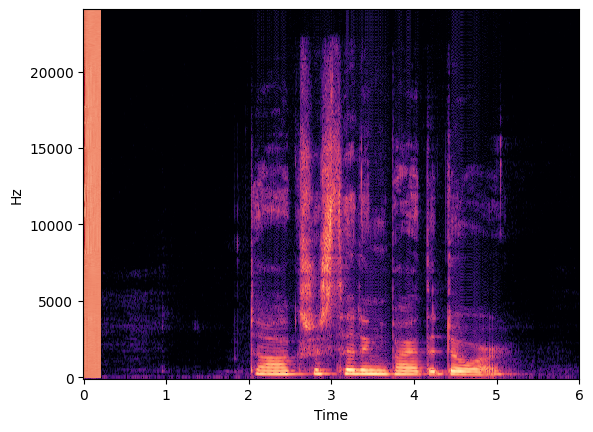

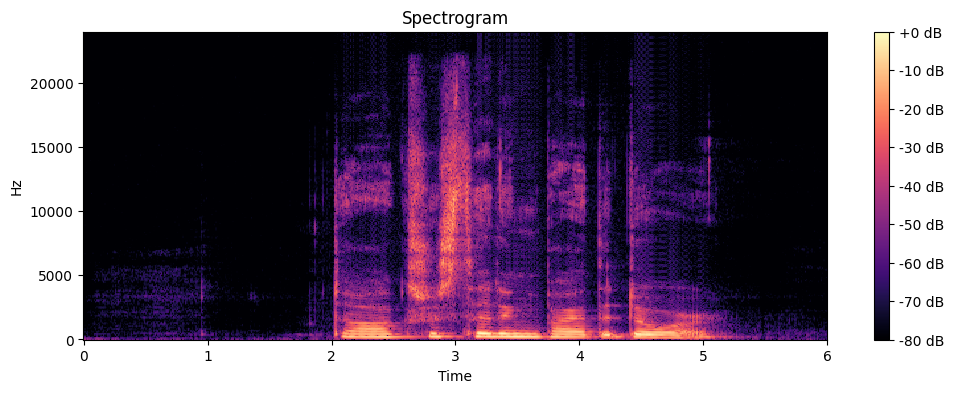

Spectrogram shape:  (513, 563)


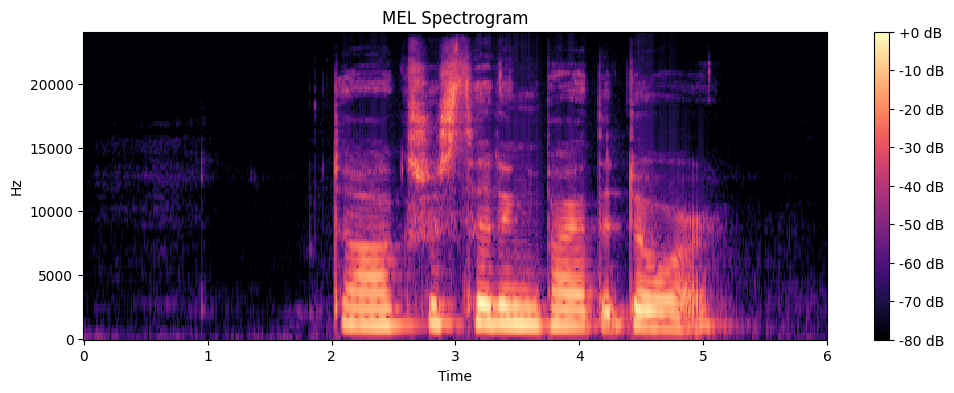

MEL spectrogram shape:  (128, 563)


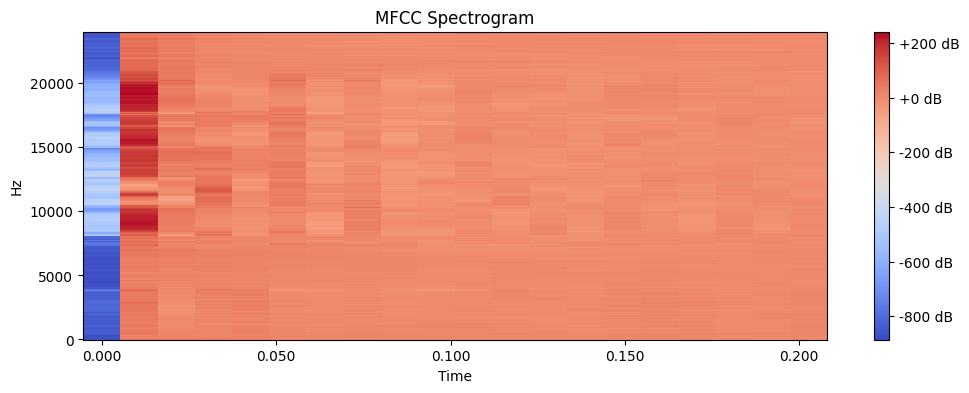

MFCC spectrogram shape:  (513, 563)


In [10]:
def getMELspectrogram(audio, sample_rate):
    mel_spec = librosa.feature.melspectrogram(y=audio,
                                              sr=sample_rate,
                                              n_fft=1024,
                                              win_length = 512,
                                              window='hamming',
                                              hop_length = 256,
                                              n_mels=128,
                                              fmax=sample_rate/2
                                             )
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
    return mel_spec_db


def getSpectrogram(audio, sample_rate):
  D = librosa.stft(y=audio, n_fft=1024, win_length=512, window='hamming', hop_length=256)  # STFT of y
  S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
  return S_db

def getMFCCspectrogram(audio, sample_rate):
# Extract MFCCs
    mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, win_length=512, window='hamming', hop_length=256, n_mels=128, fmax=sample_rate/2)
    mfccs_db = librosa.power_to_db(mfccs, ref=np.max)
    return mfccs.T

a = 525
audio, sample_rate = librosa.load(train_files[a], duration=3, sr=SAMPLE_RATE)
print(train_labels[a])
signal = np.zeros((int(SAMPLE_RATE*3,)))
signal[:len(audio)] = audio

mel_spectrogram = getMELspectrogram(signal, SAMPLE_RATE)
librosa.display.specshow(mel_spectrogram, sr=SAMPLE_RATE, y_axis='hz', x_axis='time')
print('MEL spectrogram shape: ',mel_spectrogram.shape)

spectrogram = getSpectrogram(signal, SAMPLE_RATE)
librosa.display.specshow(spectrogram, sr=SAMPLE_RATE, x_axis='time', y_axis='hz')
print('Spectrogram shape: ',spectrogram.shape)

mfcc_spectrogram = getMFCCspectrogram(signal, SAMPLE_RATE)
librosa.display.specshow(mfcc_spectrogram, sr=SAMPLE_RATE, x_axis='time', y_axis='hz')
print('MFCC spectrogram shape: ',spectrogram.shape)

spectrogram = getSpectrogram(signal, SAMPLE_RATE)
plt.figure(figsize=(12, 4))
librosa.display.specshow(spectrogram, sr=SAMPLE_RATE, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title('Spectrogram')
plt.show()
print('Spectrogram shape: ',spectrogram.shape)

mel_spectrogram = getMELspectrogram(signal, SAMPLE_RATE)
plt.figure(figsize=(12, 4))
librosa.display.specshow(mel_spectrogram, sr=SAMPLE_RATE, y_axis='hz', x_axis='time')
plt.colorbar(format='%+2.0f dB')
plt.title('MEL Spectrogram')
plt.show()
print('MEL spectrogram shape: ',mel_spectrogram.shape)

mfcc_spectrogram = getMFCCspectrogram(signal, SAMPLE_RATE)
plt.figure(figsize=(12, 4))
librosa.display.specshow(mfcc_spectrogram, sr=SAMPLE_RATE, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title('MFCC Spectrogram')
plt.show()
print('MFCC spectrogram shape: ',spectrogram.shape)



In [11]:
mel_train = []
print("Calculatin mel spectrograms for train set")
for i in range(X_train.shape[0]):
    mel_spectrogram = getMELspectrogram(X_train[i,:], sample_rate=SAMPLE_RATE)
    mel_train.append(mel_spectrogram)
    print("\r Processed {}/{} files".format(i+1,X_train.shape[0]),end='')
print('')
mel_train = np.stack(mel_train,axis=0)
del X_train
X_train = mel_train

mel_test = []
print("Calculatin mel spectrograms for test set")
for i in range(X_test.shape[0]):
    mel_spectrogram = getMELspectrogram(X_test[i,:], sample_rate=SAMPLE_RATE)
    mel_test.append(mel_spectrogram)
    print("\r Processed {}/{} files".format(i+1,X_test.shape[0]),end='')
print('')
mel_test = np.stack(mel_test,axis=0)
del X_test
X_test = mel_test

print(f'X_train:{X_train.shape}, Y_train:{Y_train.shape}')
print(f'X_test:{X_test.shape}, Y_test:{Y_test.shape}')

Calculatin mel spectrograms for train set
 Processed 3780/3780 files
Calculatin mel spectrograms for test set
 Processed 432/432 files
X_train:(3780, 128, 563), Y_train:(3780,)
X_test:(432, 128, 563), Y_test:(432,)


In [12]:
print(f'X_train:{X_train.shape}, Y_train:{Y_train.shape}')

X_train:(3780, 128, 563), Y_train:(3780,)


In [13]:
import torch
import torch.nn as nn

class ParallelModel(nn.Module):
    def __init__(self,num_emotions):
        super().__init__()
        # conv block
        self.conv2Dblock = nn.Sequential(
            # 1. conv block
            nn.Conv2d(in_channels=1,
                       out_channels=16,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.3),
            # 2. conv block
            nn.Conv2d(in_channels=16,
                       out_channels=32,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.3),
            # 3. conv block
            nn.Conv2d(in_channels=32,
                       out_channels=64,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.3),
            # 4. conv block
            nn.Conv2d(in_channels=64,
                       out_channels=64,
                       kernel_size=3,
                       stride=1,
                       padding=1
                      ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=4, stride=4),
            nn.Dropout(p=0.3)
        )
        # LSTM block
        self.lstm_maxpool = nn.MaxPool2d(kernel_size=[2,4], stride=[2,4])
        hidden_size = 128
        self.lstm = nn.LSTM(input_size=64,hidden_size=hidden_size,bidirectional=True, batch_first=True)
        self.dropout_lstm = nn.Dropout(0.1)
        self.attention_linear = nn.Linear(2*hidden_size,1) # 2*hidden_size for the 2 outputs of bidir LSTM
        # Linear softmax layer
        self.out_linear = nn.Linear(2*hidden_size+256,num_emotions)
        self.dropout_linear = nn.Dropout(p=0)
        self.out_softmax = nn.Softmax(dim=1)
    def forward(self,x):
        # conv embedding
        conv_embedding = self.conv2Dblock(x) #(b,channel,freq,time)
        conv_embedding = torch.flatten(conv_embedding, start_dim=1) # do not flatten batch dimension
        # lstm embedding
        x_reduced = self.lstm_maxpool(x)
        x_reduced = torch.squeeze(x_reduced,1)
        x_reduced = x_reduced.permute(0,2,1) # (b,t,freq)
        lstm_embedding, (h,c) = self.lstm(x_reduced) # (b, time, hidden_size*2)
        lstm_embedding = self.dropout_lstm(lstm_embedding)
        batch_size,T,_ = lstm_embedding.shape
        attention_weights = [None]*T
        for t in range(T):
            embedding = lstm_embedding[:,t,:]
            attention_weights[t] = self.attention_linear(embedding)
        attention_weights_norm = nn.functional.softmax(torch.stack(attention_weights,-1),-1)
        attention = torch.bmm(attention_weights_norm,lstm_embedding) # (Bx1xT)*(B,T,hidden_size*2)=(B,1,2*hidden_size)
        attention = torch.squeeze(attention, 1)
        # concatenate
        complete_embedding = torch.cat([conv_embedding, attention], dim=1)

        output_logits = self.out_linear(complete_embedding)
        output_logits = self.dropout_linear(output_logits)
        output_softmax = self.out_softmax(output_logits)
        return output_logits, output_softmax, attention_weights_norm

In [14]:
def loss_fnc(predictions, targets):
    return nn.CrossEntropyLoss()(input=predictions,target=targets)

In [15]:
# SKIP IF TESTING
def make_train_step(model, loss_fnc, optimizer):
    def train_step(X,Y):
        # set model to train mode
        model.train()
        # forward pass
        output_logits, output_softmax, attention_weights_norm = model(X)
        predictions = torch.argmax(output_softmax,dim=1)
        accuracy = torch.sum(Y==predictions)/float(len(Y))
        # compute loss
        loss = loss_fnc(output_logits, Y)
        # compute gradients
        loss.backward()
        # update parameters and zero gradients
        optimizer.step()
        optimizer.zero_grad()
        return loss.item(), accuracy*100
    return train_step

After the melspectrogram training/testing, add more lines at the end for the other spectrogram types.

In [16]:
from sklearn.preprocessing import StandardScaler

X_train = np.expand_dims(X_train,1)
X_test = np.expand_dims(X_test,1)

'''X_train = X_test = np.squeeze(X_train)
X_test = np.squeeze(X_test)

X_train = np.expand_dims(X_train,1)
X_test = np.expand_dims(X_test,1)'''

scaler = StandardScaler()

print(X_train.shape)
b,c,h,w = X_train.shape
X_train = np.reshape(X_train, newshape=(b,-1))
X_train = scaler.fit_transform(X_train)
X_train = np.reshape(X_train, newshape=(b,c,h,w))

print(X_test.shape)
b,c,h,w = X_test.shape
X_test = np.reshape(X_test, newshape=(b,-1))
X_test = scaler.fit_transform(X_test) # transform
X_test = np.reshape(X_test, newshape=(b,c,h,w))

(3780, 1, 128, 563)
(432, 1, 128, 563)


In [17]:
# SKIP IF TESTING
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Selected device is {}'.format(device))

EPOCHS=150
DATASET_SIZE = X_train.shape[0]
BATCH_SIZE = 32
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Selected device is {}'.format(device))
model = ParallelModel(num_emotions=len(label_dict)).to(device)
print('Number of trainable params: ',sum(p.numel() for p in model.parameters()) )
OPTIMIZER = torch.optim.SGD(model.parameters(),lr=0.005, weight_decay=.008, momentum=0.8)

train_step = make_train_step(model, loss_fnc, optimizer=OPTIMIZER)
losses=[]
for epoch in range(EPOCHS):
    # schuffle data
    ind = np.random.permutation(DATASET_SIZE)
    X_train = X_train[ind,:,:,:]
    Y_train = Y_train[ind]
    epoch_acc = 0
    epoch_loss = 0
    iters = int(DATASET_SIZE / BATCH_SIZE)
    for i in range(iters):
        batch_start = i * BATCH_SIZE
        batch_end = min(batch_start + BATCH_SIZE, DATASET_SIZE)
        actual_batch_size = batch_end-batch_start
        X = X_train[batch_start:batch_end,:,:,:]
        Y = Y_train[batch_start:batch_end]
        X_tensor = torch.tensor(X,device=device).float()
        Y_tensor = torch.tensor(Y, dtype=torch.long,device=device)
        loss, acc = train_step(X_tensor,Y_tensor)
        epoch_acc += acc*actual_batch_size/DATASET_SIZE
        epoch_loss += loss*actual_batch_size/DATASET_SIZE
        print(f"\r Epoch {epoch}: iteration {i}/{iters}",end='')
    losses.append(epoch_loss)
    print('')
    print(f"Epoch {epoch} --> loss:{epoch_loss:.4f} acc:{epoch_acc:.2f}")


Selected device is cuda
Selected device is cuda
Number of trainable params:  263593
 Epoch 0: iteration 117/118
Epoch 0 --> loss:1.7125 acc:25.87
 Epoch 1: iteration 117/118
Epoch 1 --> loss:1.5268 acc:34.26
 Epoch 2: iteration 117/118
Epoch 2 --> loss:1.4288 acc:37.09
 Epoch 3: iteration 117/118
Epoch 3 --> loss:1.3651 acc:40.05
 Epoch 4: iteration 117/118
Epoch 4 --> loss:1.3363 acc:42.04
 Epoch 5: iteration 117/118
Epoch 5 --> loss:1.2801 acc:45.32
 Epoch 6: iteration 117/118
Epoch 6 --> loss:1.2297 acc:47.14
 Epoch 7: iteration 117/118
Epoch 7 --> loss:1.2230 acc:46.85
 Epoch 8: iteration 117/118
Epoch 8 --> loss:1.1936 acc:49.10
 Epoch 9: iteration 117/118
Epoch 9 --> loss:1.1649 acc:51.22
 Epoch 10: iteration 117/118
Epoch 10 --> loss:1.1388 acc:51.22
 Epoch 11: iteration 117/118
Epoch 11 --> loss:1.1258 acc:51.67
 Epoch 12: iteration 117/118
Epoch 12 --> loss:1.1097 acc:53.25
 Epoch 13: iteration 117/118
Epoch 13 --> loss:1.1029 acc:53.15
 Epoch 14: iteration 117/118
Epoch 14 --

In [19]:
SAVE_PATH = os.path.join(os.getcwd(),'models')
os.makedirs('models',exist_ok=True)
torch.save(model.state_dict(),os.path.join(SAVE_PATH,'ravdes_model.pt'))
print('Model is saved to {}'.format(os.path.join(SAVE_PATH,'ravdes_model.pt')))

Model is saved to /content/models/ravdes_model.pt


In [21]:
LOAD_PATH = os.path.join(os.getcwd(),'models')

model = ParallelModel(len(label_dict))
model.load_state_dict(torch.load('/content/models/ravdes_model.pt')) # "/content/drive/MyDrive/COSMOSPosterProject/cnn_lstm_parallel_model75.pt"
print('Model is loaded from {}'.format('ravdes.pt'))

Model is loaded from ravdes.pt


<ipython-input-21-b88c1400b351>:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('/content/models/ravdes_model.pt')) # "/content/drive/MyDri

In [34]:
MODEL_PATH = "/content/drive/MyDrive/COSMOSPosterProject/cnn_lstm_parallel_model75.pt"# '/content/models/ravdess_model.pt'
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize Model
model = ParallelModel(8)

# Load model weights
checkpoint = torch.load(MODEL_PATH, map_location="cpu")
model.load_state_dict(checkpoint, strict=False)
model.to(DEVICE)

<ipython-input-34-68f70d6ef8d8>:8: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(MODEL_PATH, map_location="cpu")


ParallelModel(
  (conv2Dblock): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dropout(p=0.3, inplace=False)
    (5): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (9): Dropout(p=0.3, inplace=False)
    (10): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (14): Dropout(p=0.3, inplace=False)
    (15): Conv2d(64, 64, kernel_size=(3, 3)

In [22]:
def validate(X,Y):
    with torch.no_grad():
        model.eval()
        output_logits, output_softmax, attention_weights_norm = model(X)
        print(output_softmax)
        predictions = torch.argmax(output_softmax,dim=1)
        accuracy = torch.sum(Y==predictions)/float(len(Y))
        loss = loss_fnc(output_logits,Y)
    return loss.item(), accuracy*100, predictions, output_softmax

In [23]:
import torch
import sklearn.metrics as metrics


if torch.cuda.is_available():
    model.cuda()


X_test_tensor = torch.tensor(X_test, device=device).float()
Y_test_tensor = torch.tensor(Y_test, dtype=torch.long, device=device)
test_loss, test_acc, predictions, output_softmax = validate(X_test_tensor, Y_test_tensor)

outp = []
for preds in output_softmax:
  arr = []
  for j in preds:
    arr.append(j.item())
  outp.append(arr)

print(outp)
print(len(outp))
print(output_softmax)
print(output_softmax.shape)
print(output_softmax[0][0].item())
# softmax_out = predictions[0].item()
# print(softmax_out)

# print(predictions)
# print(predictions.shape)



if isinstance(predictions, torch.Tensor):
    predictions = predictions.cpu().numpy()

print(predictions)
print(test_labels)
print(predictions.shape)

inc = 0
for i in range(0, len(test_labels)):
  if (predictions[i] != test_labels[i]):
    inc += 1

print(inc)
print("Pred vs test " + str(1 - inc/len(test_labels)))


true_labels = Y_test_tensor.cpu().numpy()

recall = metrics.recall_score(true_labels, predictions, average='weighted')
f1 = metrics.f1_score(true_labels, predictions, average='weighted')

print(f'Test loss is {test_loss:.3f}')
print(f'Test accuracy is {test_acc:.2f}%')
print(f'Test recall is {recall:.2f}')
print(f'Test F1 score is {f1:.2f}')

tensor([[3.0644e-01, 6.4462e-01, 2.0228e-02,  ..., 1.2318e-03, 1.2311e-03,
         1.2388e-03],
        [1.0549e-01, 8.6879e-01, 1.2053e-02,  ..., 3.8429e-04, 3.8790e-04,
         3.8504e-04],
        [4.9125e-01, 3.7136e-01, 9.5982e-02,  ..., 2.5918e-03, 2.6177e-03,
         2.5946e-03],
        ...,
        [1.0138e-03, 9.3410e-05, 1.1655e-03,  ..., 9.9068e-05, 9.9633e-05,
         9.9607e-05],
        [2.7003e-03, 2.4640e-03, 1.7932e-03,  ..., 4.2305e-04, 4.2630e-04,
         4.2234e-04],
        [1.9531e-02, 1.2008e-02, 3.2741e-03,  ..., 2.2081e-03, 2.2028e-03,
         2.2029e-03]], device='cuda:0')
[[0.3064447343349457, 0.6446175575256348, 0.020227674394845963, 0.024277502670884132, 0.000730912433937192, 0.0012318072840571404, 0.001231080386787653, 0.001238793833181262], [0.10549292713403702, 0.8687944412231445, 0.012052839621901512, 0.008573748171329498, 0.003928870428353548, 0.00038428863626904786, 0.0003879029827658087, 0.000385042920242995], [0.49125418066978455, 0.371361076

0 0.7106481481481481
1 0.7129629629629629
2 0.7152777777777778
3 0.7175925925925926
4 0.7199074074074074
5 0.7222222222222222
6 0.7268518518518519
7 0.7268518518518519
8 0.7268518518518519
9 0.7337962962962963
10 0.7361111111111112
11 0.7361111111111112
12 0.7361111111111112
13 0.7430555555555556
14 0.7430555555555556
15 0.7453703703703703
16 0.7453703703703703
17 0.75
18 0.75
19 0.7592592592592593
20 0.7615740740740741
21 0.7615740740740741
22 0.7662037037037037
23 0.7662037037037037
24 0.7662037037037037
25 0.7685185185185185
26 0.7685185185185185
27 0.7685185185185185
28 0.7731481481481481
29 0.7754629629629629
30 0.7754629629629629
31 0.7777777777777778
32 0.7870370370370371
33 0.7870370370370371
34 0.7916666666666666
35 0.8078703703703703
36 0.8101851851851852
37 0.8125
38 0.8148148148148148
39 0.8125
40 0.8125
41 0.8101851851851852
42 0.8101851851851852
43 0.8055555555555556
44 0.8009259259259259
45 0.7962962962962963
46 0.7847222222222222
47 0.7777777777777778
48 0.7754629629629

Text(0, 0.5, 'accuracy (%)')

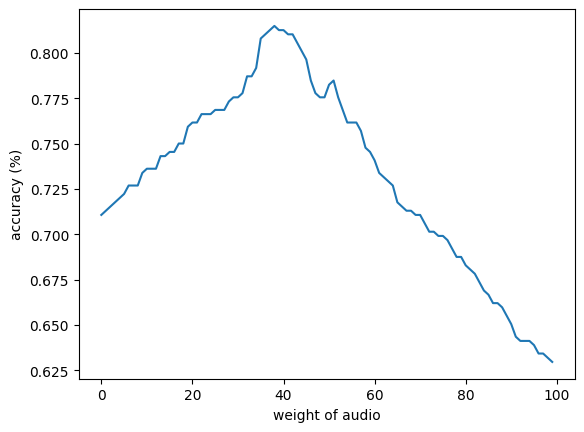

In [ ]:
import numpy as np
softmaxes = np.load('/content/drive/MyDrive/COSMOSPosterProject/final_arr_video_softmaxes.npy')
files = np.load('/content/drive/MyDrive/COSMOSPosterProject/final_arr_video_files.npy')
for i in range(len(softmaxes)):
  tmp = softmaxes[i][0]
  softmaxes[i][0] = softmaxes[i][3]
  softmaxes[i][3] = tmp
final_arr_video = []
for i in range(len(softmaxes)):
    final_arr_video.append([files[i][3:20], softmaxes[i]])

final_arr_audio = []
for i in range(len(outp)):
    new_out_p = []
    for j in range(5):
        new_out_p.append(outp[i][j])
    final_arr_audio.append([test_files[i].split('/')[len(test_files[i].split('/'))-1][3:20], new_out_p])


total = 432
correct = 0

pred_arr = []
audio_weighted = []
accuracy = []
for weight in range(100):
    correct = 0
    for i in range(len(final_arr_audio)):
        for j in range(len(final_arr_video)):
            if (final_arr_video[j][0] == final_arr_audio[i][0]):
                ls = []
                for k in range(len(final_arr_audio[i][1])):
                    ls.append(final_arr_audio[i][1][k] * weight/100 + final_arr_video[j][1][k] * ((100-weight)/100))
                ls1 = [i/2 for i in ls]

                #print([ls, final_arr_video[j][0]])
                #print([final_arr_video[i][1], final_arr_video[j][0]])
                #print([final_arr_audio[i][1], final_arr_video[j][0]])

                max_idx = 0
                max_val = 0
                for k in range(len(ls)):
                    if (ls[k] > max_val):
                        max_idx = k
                        max_val = ls[k]
                if (max_idx == test_labels[i]):
                    correct += 1

    print(str(weight) + ' ' + str(correct/total))
    accuracy.append(correct/total)
    audio_weighted.append(weight)

print(max(accuracy))

plt.figure()
plt.plot(audio_weighted, accuracy)
plt.xlabel('weight of audio')
plt.ylabel('accuracy (%)')






In [ ]:
for i in range(len(final_arr_audio)):
  for j in range(len(final_arr_video)):
    if (final_arr_video[j][0] == final_arr_audio[i][0]):
      #print(final_arr_video[i])
      #print(final_arr_audio[j])
      #print()
      #print()
      ls = []
      for k in range(len(final_arr_audio[i][1])):
        ls.append(final_arr_audio[i][1][k] * 50/100 + final_arr_video[j][1][k] * 50/100)
      ls1 = [i/2 for i in ls]

      #print([ls, final_arr_video[j][0]])
      #print([final_arr_video[i][1], final_arr_video[j][0]])
      #print([final_arr_audio[i][1], final_arr_video[j][0]])

      max_idx = 0
      max_val = 0
      for k in range(len(ls)):
        if (ls[k] > max_val):
          max_idx = k
          max_val = ls[k]
      if (max_idx == test_labels[i]):
        correct += 1
      pred_arr.append(max_idx)

print(correct/432)
print(len(pred_arr))

1.412037037037037
432


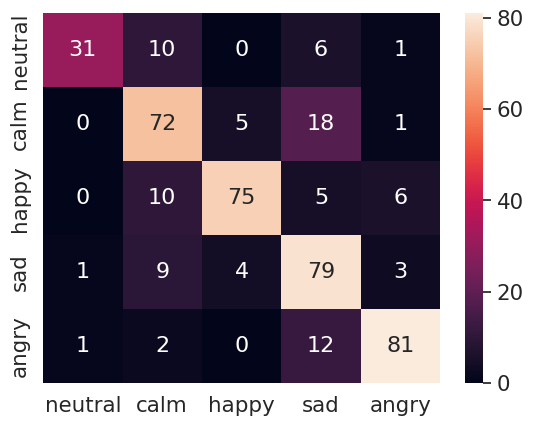

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sn

label_dict = {0: 'neutral', 1: 'calm', 2: 'happy', 3: 'sad', 4: 'angry', 5: 'fearful', 6: 'disgust', 7 : 'surprised'}

cm = confusion_matrix(Y_test, pred_arr)
names = [label_dict[ind] for ind in range(5)]
df_cm = pd.DataFrame(cm, index=names, columns=names)
# plt.figure(figsize=(10,7))
sn.set(font_scale=1.4)
sn.heatmap(df_cm, annot=True, annot_kws={"size": 16})
plt.show()

DON